**Цель работы**: Научиться корректно подбирать гиперпараметры моделей с помощью кросс-валидации, сравнивать стратегии поиска и оценивать влияние гиперпараметров на качество модели.

# Выбор задачи и модели

- Использовать задачу из лабораторной №1 или №2 по выбору
- Зафиксировать исходные параметры модели и качество до оптимизации

In [ ]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import randint, uniform  # распределения для Random Search: randint — целые, uniform — равномерное
from sklearn.model_selection import (train_test_split, StratifiedKFold, GridSearchCV, RandomizedSearchCV,
                                     cross_val_score, validation_curve)  # validation_curve — кривые зависимости метрики от гиперпараметра
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer  # заполнение пропусков (медианой/модой)
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import f1_score

RS = 42  # фиксированный random_state для воспроизводимости разбиения

df = pd.read_csv("data/Titanic-Dataset.csv") 
X, y = df.drop(columns=["Survived", "PassengerId", "Name", "Ticket", "Cabin"]), df["Survived"]  # X — признаки, y — целевая переменная
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=RS, stratify=y)

prep = ColumnTransformer([
    ("num", make_pipeline(SimpleImputer(strategy="median")), ["Pclass", "Age", "SibSp", "Parch", "Fare"]),
    ("cat", make_pipeline(SimpleImputer(strategy="most_frequent"), OneHotEncoder(drop="if_binary", sparse_output=False)), ["Sex", "Embarked"]),
])  # для числовых масштабирование не нужно — деревья не чувствительны к масштабу; у категориальных пропуски заполнены модой, sparse_output выдаёт плотную матрицу


base = Pipeline([("prep", prep), ("rf", RandomForestClassifier(n_estimators=100, random_state=RS, n_jobs=-1))])  # исходная модель с параметрами по умолчанию
# Pipeline гарантирует, что препроцессинг обучается внутри каждого фолда

cv = StratifiedKFold(5, shuffle=True, random_state=RS)

p = base["rf"].get_params()  # получаем все параметры rf
print("Исходные параметры:", {k: p[k] for k in ["n_estimators", "max_depth", "min_samples_leaf", "max_features"]})

cv_base = cross_val_score(base, X_train, y_train, cv=cv, scoring="f1")  # оцениваем baseline
print(f"Исходное качество: F1 CV = {cv_base.mean():.3f} ± {cv_base.std():.3f}")

Исходные параметры: {'n_estimators': 100, 'max_depth': None, 'min_samples_leaf': 1, 'max_features': 'sqrt'}
Исходное качество: F1 CV = 0.736 ± 0.026


**Обоснование выбора.** Задача из лабораторной №2 (Titanic), модель - **Random Forest**, основная метрика - F1 по классу «выжил». 

Исходная модель - случайный лес с параметрами по умолчанию (`n_estimators=100`, `max_depth=None`, `min_samples_leaf=1`, `max_features="sqrt"`). Параметр `n_estimators` фиксирован на 100 во всех экспериментах и не подбирается.

Разбиение train/test и препроцессинг те же, что в лабораторной №2: 
- тест не используется ни при подборе, ни при построении кривых; 
- качество исходной модели зафиксировано по кросс-валидации на train, а на тесте она будет оценена один раз в разделе «Финальная модель», вместе с остальными.

# Гиперпараметры

- Выбрать не менее 3 значимых гиперпараметров выбранного алгоритма
- Для каждого:
    - объяснить его смысл
    - определить разумный диапазон значений
    - предположить, как его изменение может повлиять на модель


In [ ]:
grid_params = {"rf__max_depth": [3, 5, 8, None],
               "rf__min_samples_leaf": [1, 3, 5, 10],
               "rf__max_features": ["sqrt", 0.5, 1.0]}  # префикс "rf__" говорит GridSearchCV, что параметр принадлежит шагу "rf" в Pipeline

rand_params = {"rf__max_depth": randint(2, 16),
               "rf__min_samples_leaf": randint(1, 16),
               "rf__max_features": uniform(0.2, 0.8)}  # Random Search пробует новые значения в каждой итерации

print("Комбинаций в сетке:", np.prod([len(v) for v in grid_params.values()]))

Комбинаций в сетке: 48


Выбраны три гиперпараметра, которые управляют сложностью модели и разнообразием деревьев. Остальные параметры оставлены по умолчанию.

| Гиперпараметр | Смысл | Диапазон | Ожидаемое влияние на модель|
|---|---|---|---|
| `max_depth` | максимальная глубина каждого дерева | 2–15 и `None` (без ограничения) | Малая глубина (1–2) - деревья слишком просты, **недообучение**. Большая глубина или `None` - деревья подгоняются под отдельные объекты и шум, растёт разрыв между train и CV (**переобучение**). |
| `min_samples_leaf` | минимальное число объектов в листе | 1–15 | Большие значения сглаживают модель (регуляризация): листья усредняют много объектов, шум не запоминается; при слишком больших значениях - недообучение. При `1` листья могут состоять из одного объекта - риск переобучения. |
| `max_features` | доля признаков, из которых выбирается лучший сплит в каждом узле | 0.2–1.0 | Малые значения делают деревья разнообразными и слабо скоррелированными. При `1.0` деревья похожи друг на друга (лес приближается к бэггингу), выигрыш от усреднения меньше. |

**Почему не подбирается `n_estimators`.** Рост числа деревьев снижает дисперсию ансамбля, но не вызывает переобучения; он только увеличивает время.

**Пространство поиска.** Для Grid Search - сетка 4 × 4 × 3 = 48 комбинаций. Для Random Search значения берутся из непрерывных/целочисленных распределений в тех же границах (`max_depth` - целое 2–15, `min_samples_leaf` - целое 1–15, `max_features` - равномерно 0.2–1.0): случайный поиск не ограничен узлами сетки и пробует новые значения в каждой итерации.

# Кросс - валидация

- Выбрать количество folds и обосновать выбор
- Тестовая выборка не должна участвовать в подборе гиперпараметров

In [3]:
folds = list(cv.split(X_train, y_train))
print("Размер обучающей части фолда / валидационной:", len(folds[0][0]), "/", len(folds[0][1]))
print("Доля выживших в валидационных фолдах:", [round(float(y_train.iloc[va].mean()), 3) for _, va in folds])

Размер обучающей части фолда / валидационной: 569 / 143
Доля выживших в валидационных фолдах: [0.385, 0.385, 0.387, 0.38, 0.38]


**Число фолдов:** 5, стратифицированные (`StratifiedKFold`, перемешивание, `random_state=42`). Обучающая выборка небольшая (712 объектов), поэтому:
- 5 фолдов оптимально: на каждой итерации модель учится на 80% train (≈ 570 объектов), близко к размеру полной выборки, а валидационный фолд (≈ 142 объекта, ≈ 54 выживших) достаточно велик для осмысленной оценки F1;
- 3 фолда дали бы более пессимистичную оценку (обучение на 2/3 данных), 10 фолдов - более маленькие валидационные части (≈ 71 объект), шумную оценку по каждому фолду и вдвое большее время;
- стратификация сохраняет долю выживших (≈ 38%) в каждом фолде, это важно для F1;
- одни и те же фолды (фиксированный `random_state`) используются для всех моделей и поисков, поэтому их результаты сопоставимы.

**Зачем нужна кросс-валидация.** Она оценивает качество на данных, не участвовавших в обучении, и при этом использует каждый объект train и для обучения, и для валидации, а усреднение по фолдам даёт более надёжную оценку и позволяет увидеть её разброс. Благодаря этому гиперпараметры можно выбирать, не трогая тест.

**Почему одного разбиения train/test недостаточно для подбора параметров.**
- Оценка по одному разбиению зависит от того, какие именно объекты в него попали: при другом разбиении порядок моделей мог бы измениться; на небольшом отложенном наборе шум оценки сравним с различием между конфигурациями.
- Если подбирать параметры по этому же отложенному набору, он перестаёт быть независимым: нужен ещё один набор для финальной оценки. Один train/test даёт только одну из двух ролей (выбор или финальная проверка), CV позволяет разделить их.

**Что произойдёт, если многократно выбирать гиперпараметры по результату на test.** Выбор будет подгонять решение под конкретные объекты теста: из многих конфигураций «победит» та, которой повезло на этой выборке. Тест перестанет быть независимым, оценка станет завышенной и на новых данных качество окажется хуже обещанного.

# Grid Search

- Провести поиск гиперпараметров по заранее заданной сетке
- Зафиксировать:
    - пространство поиска
    - количество проверенных комбинаций
    - лучший набор гиперпараметров
    - значение метрики на кросс-валидации
    - время выполнения поиска

In [ ]:
pipe = Pipeline([("prep", prep), ("rf", RandomForestClassifier(n_estimators=100, random_state=RS, n_jobs=-1))]) 
# создаём новый Pipeline, чтобы избежать побочных эффектов от уже обученного

def report(name, search, seconds):
    n = len(search.cv_results_["params"])  # число проверенных комбинаций
    std = search.cv_results_["std_test_score"][search.best_index_]  # std на лучшей комбинации
    print(f"{name}: комбинаций {n} (обучений {n * cv.get_n_splits()}), время {seconds:.1f} с")
    print(f"  лучшие параметры: {search.best_params_}")
    print(f"  F1 CV = {search.best_score_:.3f} ± {std:.3f}")

t0 = time.perf_counter()
grid = GridSearchCV(pipe, grid_params, scoring="f1", cv=cv).fit(X_train, y_train)
t_grid = time.perf_counter() - t0

print("Пространство поиска:", grid_params)
report("Grid Search", grid, t_grid)

Пространство поиска: {'rf__max_depth': [3, 5, 8, None], 'rf__min_samples_leaf': [1, 3, 5, 10], 'rf__max_features': ['sqrt', 0.5, 1.0]}
Grid Search: комбинаций 48 (обучений 240), время 36.8 с
  лучшие параметры: {'rf__max_depth': 8, 'rf__max_features': 1.0, 'rf__min_samples_leaf': 1}
  F1 CV = 0.758 ± 0.025


# Random Search

- Провести поиск с помощью случайного выбора комбинаций гиперпараметров
- Сравнить Random Search с Grid Search:
    - по найденному качеству
    - количеству проверенных комбинаций
    - времени выполнения

In [ ]:
N_ITER = 24  # число итераций Random Search
t0 = time.perf_counter()
rand = RandomizedSearchCV(pipe, rand_params, n_iter=N_ITER, scoring="f1", cv=cv, random_state=RS).fit(X_train, y_train)
t_rand = time.perf_counter() - t0

report("Random Search", rand, t_rand)
pd.DataFrame({"комбинаций": [len(grid.cv_results_["params"]), N_ITER], "F1 CV (лучший)": [grid.best_score_, rand.best_score_],
              "время, с": [t_grid, t_rand]}, index=["Grid Search", "Random Search"]).round(3)

Random Search: комбинаций 24 (обучений 120), время 17.3 с
  лучшие параметры: {'rf__max_depth': 13, 'rf__max_features': np.float64(0.9508421672126002), 'rf__min_samples_leaf': 2}
  F1 CV = 0.755 ± 0.032


,комбинаций,F1 CV (лучший),"время, с"
Grid Search,48,0.758,35.743
Random Search,24,0.755,17.296


**Сравнение.**
- *Качество.* Лучший F1 на кросс-валидации у Random Search. Он практически совпадает с Grid Search, хотя проверил вдвое меньше комбинаций. 
- *Число комбинаций и время.* Grid Search - 48 комбинаций, Random Search - 24; время растёт пропорционально числу обучений.

**Когда случайный поиск предпочтительнее полного перебора.**
- гиперпараметров много, а действительно важны лишь некоторые: сетка тратит много ресурсов на повторение одних и тех же значений важного параметра при изменении неважных, а случайный поиск в каждой итерации пробует новое значение каждого параметра.
- параметры непрерывные или диапазоны широкие: сетка вынуждена грубо дискретизировать их, случайный поиск покрывает весь диапазон.
- ресурс ограничен: число итераций задаётся напрямую (`n_iter`), а размер сетки растёт экспоненциально с числом параметров.
- нет информации о том, где лежит оптимум: случайная выборка не зависит от удачного выбора узлов сетки.

Полный перебор оправдан, когда параметров мало, их значения дискретны, а вычисления дешёвые (как в данной задаче).

# Влияние гиперпараметров

- Для выбранных гиперпараметров исследовать зависимость качества модели от их значений
- Визуализировать результаты

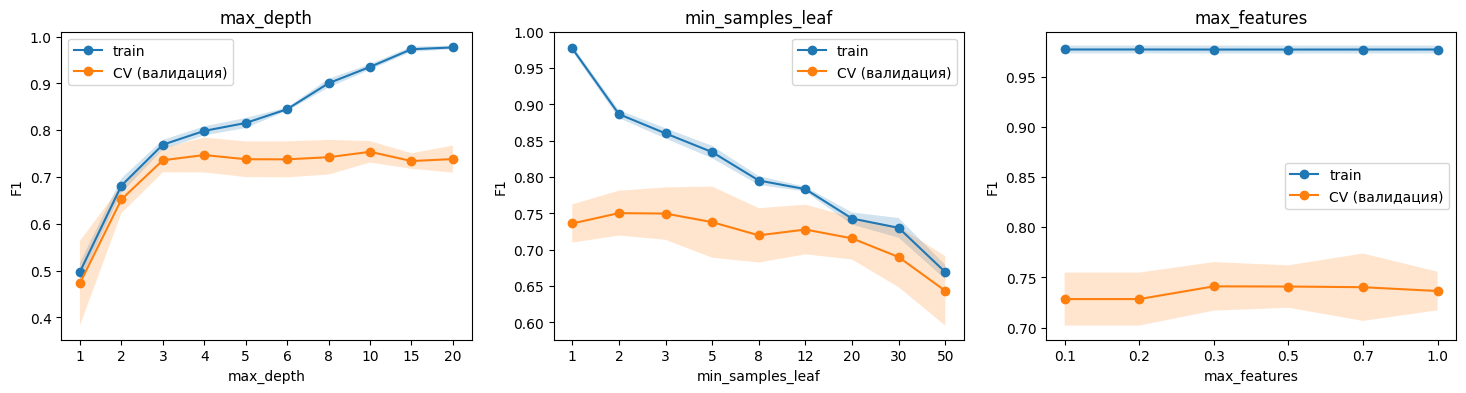

In [ ]:
ranges = {
    "rf__max_depth": [1, 2, 3, 4, 5, 6, 8, 10, 15, 20],  # диапазон для кривой
    "rf__min_samples_leaf": [1, 2, 3, 5, 8, 12, 20, 30, 50],
    "rf__max_features": [0.1, 0.2, 0.3, 0.5, 0.7, 1.0],
}

fig, ax = plt.subplots(1, 3, figsize=(18, 4))
for a, (param, vals) in zip(ax, ranges.items()):
    train_s, cv_s = validation_curve(base, X_train, y_train, param_name=param, param_range=vals, cv=cv, scoring="f1") # кривые валидации
    x = range(len(vals))
    for s, label in [(train_s, "train"), (cv_s, "CV (валидация)")]:
        a.plot(x, s.mean(1), marker="o", label=label)
        a.fill_between(x, s.mean(1) - s.std(1), s.mean(1) + s.std(1), alpha=0.2)
    a.set(xticks=list(x), xticklabels=vals, xlabel=param.split("__")[1], ylabel="F1", title=param.split("__")[1])
    a.legend()
plt.show()

Кривые построены на обучающей выборке по кросс-валидации: меняется один параметр, остальные соответствуют исходной модели. Линия - среднее по фолдам, полоса - ±1 std. Кривые нужны для понимания влияния параметров; сами параметры выбирают Grid и Random Search.

**`max_depth`.**
- *Недообучение* (глубина 1–2): и train, и CV F1 низкие и близки между собой - деревья слишком просты (не успевают разделить пассажиров по `Sex` и `Pclass`).
- *Разумная сложность* (глубина 3–8): CV F1 максимален и выходит на плато.
- *Переобучение* (глубина ≥ 10): F1 на train стремится к 1, а CV не растёт (остаётся на плато или чуть снижается) - растёт разрыв, то есть модель запоминает обучающие объекты. Лес переобучается мягче одиночного дерева из-за усреднения, поэтому CV почти не падает.

**`min_samples_leaf`.** Картина зеркальная: при 1 листья «узкие», train F1 максимален при большом разрыве с CV (переобучение); при 3–10 разрыв сокращается, а CV F1 максимален (разумная сложность); при очень больших значениях (30–50) листья слишком крупные, обе кривые падают (недообучение).

**`max_features`.** Малые значения (0.1–0.2) ослабляют отдельные деревья (в узел может попасть выборка без `Sex`), CV F1 ниже. Средние значения дают лучший баланс между качеством деревьев и их разнообразием. При 1.0 деревья похожи друг на друга, и эффект усреднения слабее: train F1 высокий, прирост CV отсутствует. Чувствительность к этому параметру обычно меньше, чем к `max_depth` и `min_samples_leaf`.

**Общий вывод.** Параметры `max_depth` и `min_samples_leaf` управляют сложностью деревьев и дают компромисс «смещение - дисперсия»; широкая плоская область вокруг оптимума объясняет, почему Grid и Random Search находят близкие по качеству решения, а выигрыш относительно настроек по умолчанию невелик.

# Финальная модель

- После завершения подбора обучить модель с выбранными гиперпараметрами и после этого оценить её на тестовой выборке
- Сравнить три результата: исходную модель, лучший результат Grid Search и лучший результат Random Search
- Для каждой модели указать CV score и Test score


In [ ]:
models = {"Исходная модель": base, "Grid Search": grid.best_estimator_, "Random Search": rand.best_estimator_}
cv_scores = {"Исходная модель": cv_base.mean(), "Grid Search": grid.best_score_, "Random Search": rand.best_score_}

base.fit(X_train, y_train)  # дообучаем baseline на всём train
final = pd.DataFrame({"CV F1": cv_scores,
                      "Test F1": {n: f1_score(y_test, m.predict(X_test)) for n, m in models.items()}})
final["Δ CV"] = final["CV F1"] - final.loc["Исходная модель", "CV F1"]  # разница CV относительно baseline: положительная = лучше
final["Δ Test"] = final["Test F1"] - final.loc["Исходная модель", "Test F1"]
final.round(3)

,CV F1,Test F1,Δ CV,Δ Test
Исходная модель,0.736,0.741,0.000,0.000
Grid Search,0.758,0.714,0.022,-0.026
Random Search,0.755,0.724,0.019,-0.016


Лучшие модели выбраны по результатам кросс-валидации на train и дообучены на всём train; тест использован один раз, только для оценки уже выбранных решений.

**Насколько оптимизация улучшила качество.** На кросс-валидации Grid Search и Random Search дают небольшой прирост F1 относительно исходной модели. Для такой задачи (малое число признаков, один главный признак - `Sex`) случайный лес с параметрами по умолчанию уже близок к оптимуму, поэтому серьёзного роста ожидать нельзя.

**Совпадает ли улучшение на CV с результатом на test.** Прирост на test оказался отрицательным. Причины:
1. **Оптимистичность CV-оценки лучшей конфигурации.** `best_score_` - максимум по десяткам конфигураций; среди многих почти одинаковых вариантов «победитель» частично выигрывает за счёт случайного шума на фолдах. Его CV-оценка завышена даже без использования теста. Тест как независимая выборка эту завышенность не воспроизводит.
2. **Малый размер теста.** 179 объектов (≈ 69 выживших): разница между моделями - сотые доли, такой прирост лежит внутри шума и не позволяет заключить, что одна модель лучше другой.
3. **Прирост сам по себе мал:** разница между исходной и настроенной моделями сопоставима с разбросом по фолдам.
4. **Различие выборок:** фолды и тест - разные случайные подвыборки, на них модели могут вести себя по-разному.

*Поэтому корректный вывод - не «Grid Search лучше на 0.02», а «оптимизация параметров даёт небольшой выигрыш, статистически трудноотличимый от шума; Grid и Random Search сопоставимы».*

# Анализ устойчивости

- Посмотреть не только на среднее значение метрики на кросс-валидации, но и на результаты отдельных folds
- Оценить разброс значений


,Исходная модель,Grid Search,Random Search
fold 1,0.774,0.774,0.766
fold 2,0.710,0.743,0.722
fold 3,0.762,0.800,0.812
fold 4,0.714,0.741,0.729
fold 5,0.720,0.735,0.745


,Исходная модель,Grid Search,Random Search
mean,0.736,0.758,0.755
std,0.029,0.028,0.036
min,0.710,0.735,0.722
max,0.774,0.800,0.812


,Grid Search,Random Search
mean,0.022,0.019
std,0.015,0.021


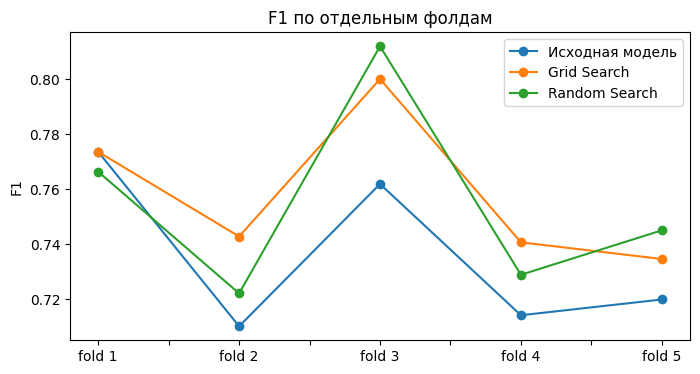

In [ ]:
folds_f1 = pd.DataFrame({n: cross_val_score(m, X_train, y_train, cv=cv, scoring="f1") for n, m in models.items()},
                        index=[f"fold {i + 1}" for i in range(cv.get_n_splits())])  # для каждой модели заново считаем CV на train
display(folds_f1.round(3))
display(folds_f1.agg(["mean", "std", "min", "max"]).round(3))

diff = folds_f1.sub(folds_f1["Исходная модель"], axis=0).drop(columns="Исходная модель") 
display(diff.agg(["mean", "std"]).round(3))

folds_f1.plot(marker="o", figsize=(8, 4), title="F1 по отдельным фолдам", ylabel="F1")
plt.show()

**Разброс по фолдам.** Среднее F1 скрывает вариативность: на разных фолдах значения заметно отличаются.

**Сопоставление с приростом.** Средний прирост настроенных моделей над исходной сопоставим со стандартным отклонением этих разностей: на части фолдов настроенная модель даже хуже исходной. Значит, улучшение небольшое и нестабильное, и по одному среднему делать вывод о превосходстве нельзя.

**Почему две модели с одинаковым средним качеством могут различаться по устойчивости.**
- Среднее одинаково, если у одной модели результаты ровные по всем фолдам, а у другой чередуются удачные и неудачные фолды. Вторая модель может иметь большую **дисперсию**: она сильнее зависит от состава обучающих данных, и на новых данных её результат менее предсказуем.
- Высокая дисперсия характерна для более сложных или слабо регуляризованных моделей (глубокие деревья, `min_samples_leaf = 1`), для небольших валидационных фолдов (≈ 142 объекта) и для моделей, чувствительных к отдельным объектам-выбросам.
- Модели могут ошибаться на разных группах пассажиров, и состав фолда по-разному влияет на каждую.

При равном среднем разумнее выбрать более устойчивую модель (меньший std, больший min по фолдам): она надёжнее на неизвестных данных.

# Честный эксперимент

Все решения о параметрах модели должны приниматься по результатам работы с обучающей выборкой и кросс-валидацией

In [ ]:
# проверка отсутствия утечки
assert set(X_train.index).isdisjoint(X_test.index)  # проверяем, что train и test не пересекаются по индексам объектов
# если бы пересекались, это была бы утечка; модель видела бы тест во время обучения

assert all(set(X_train.index[va]).isdisjoint(X_test.index) for _, va in cv.split(X_train, y_train))  # проверяем, что ни один валидационный фолд CV не содержит объектов из test
# это гарантирует, что тест не подсматривался даже внутри CV

print(f"Объектов в train/test: {len(X_train)}/{len(X_test)}")

Объектов в train/test: 712/179


**Как соблюдён честный протокол.**
1. Разбиение train/test сделано один раз (`random_state=42`, стратификация); тест не использовался ни при подборе гиперпараметров, ни при построении кривых влияния, ни при выборе числа фолдов и границ сетки.
2. Все решения (лучшие параметры Grid и Random Search, выводы о недо- и переобучении) приняты по кросс-валидации на train с одними и теми же фолдами. Препроцессинг внутри `Pipeline` обучается заново на обучающей части каждого фолда, поэтому в валидационные фолды не попадает информация (медианы, категории) из их собственных данных.
3. Финальные модели дообучены на всём train, и только после этого один раз оценены на тесте. Результат теста не использовался для изменения параметров.
4. Исходная модель - честный baseline: оценена тем же способом (CV на train, затем один раз на тесте).

**Ограничения.** CV-оценка лучшей конфигурации слегка завышена из-за отбора по ней (максимум среди многих), а небольшой тест даёт шумную финальную оценку. 

# Общий вывод

Подбор гиперпараметров Random Forest на задаче Titanic по кросс-валидации (5 стратифицированных фолдов) дал небольшое улучшение F1 относительно параметров по умолчанию.

Grid Search (48 комбинаций) и Random Search (24 комбинации) нашли решения сопоставимого качества, причём случайный поиск обошёлся вдвое дешевле.

Кривые влияния показали области недообучения (малая глубина, очень большие листья), разумной сложности и переобучения (глубокие деревья, листья из одного объекта); прирост на test сопоставим с шумом (малый тест, отбор «лучшего» по CV, разброс по фолдам). 

Тест использовался только для финальной проверки уже выбранных решений.